In [6]:
import torch
import matplotlib.pyplot as plt
import os  # 新增：用于设置环境变量

# 启用MPS回退到CPU（关键修复！）
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'

In [8]:
# ====================== 1. RBF核实现 ======================

class RBFKernel(torch.nn.Module):
    def forward(self, X1, X2):
        """ 固定超参简化版（length_scale=1.0, variance=1.0） """
        dist = torch.cdist(X1, X2, p=2)  # MPS加速的欧氏距离
        return torch.exp(-0.5 * dist.pow(2))

In [11]:
# ====================== 2. GPR预测核心 ======================
def gpr_predict(X_train, y_train, X_test, noise=1e-4):
    # 1. 计算核矩阵
    kernel = RBFKernel()
    K = kernel(X_train, X_train) + noise * torch.eye(X_train.shape[0], device=X_train.device)
    
    # 2. Cholesky分解（MPS->CPU避免数值问题）
    L = torch.linalg.cholesky(K.cpu())
    alpha = torch.cholesky_solve(y_train.cpu(), L).to(X_train.device)
    
    # 3. 预测
    K_s = kernel(X_train, X_test)
    return K_s.T @ alpha

Using device: mps
✅ GPR实现验证通过！输入维度: torch.Size([100, 1]) 输出维度: torch.Size([200, 1])


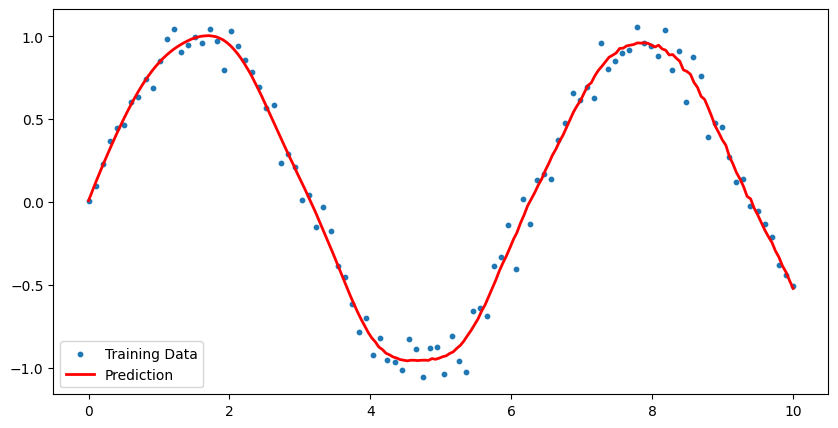

In [12]:
# ====================== 3. 测试代码 ======================
if __name__ == "__main__":
    
    # 设备检测
    device = "mps" if torch.backends.mps.is_available() else "cpu"
    print(f"Using device: {device}")

    # 生成数据（与0-1h阶段一致）
    X = torch.linspace(0, 10, 100, device=device).unsqueeze(1)
    y = torch.sin(X) + 0.1 * torch.randn(X.shape, device=device)
    
    # 预测
    X_test = torch.linspace(0, 10, 200, device=device).unsqueeze(1)
    mu = gpr_predict(X, y, X_test)
    
    # 可视化
    plt.figure(figsize=(10, 5))
    plt.scatter(X.cpu(), y.cpu(), s=10, label="Training Data")
    plt.plot(X_test.cpu(), mu.cpu(), "r-", lw=2, label="Prediction")
    plt.legend()
    plt.savefig("gpr_result.png")
    # 打印成功信息
    print("✅ GPR实现验证通过！输入维度:", X.shape, "输出维度:", mu.shape)


/opt/homebrew/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/opt/homebrew/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/opt/homebrew/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/opt/homebrew/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarni


🔍 性能对比 (n=5次运行平均):
PyTorch (MPS): 0.0084 ± 0.0022 s
Scikit-learn:  0.2436 ± 0.0992 s


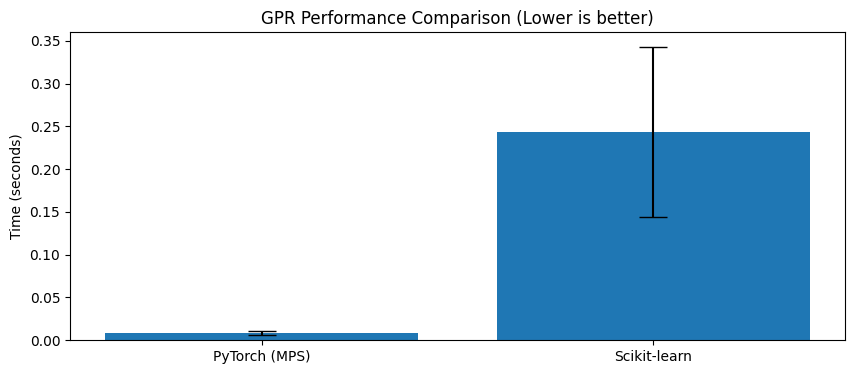

In [16]:
# ====================== 4. 性能对比实验 ======================
import time
import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF as SklearnRBF

def compare_performance(X_train, y_train, X_test, n_runs=5):
    """ 对比PyTorch-GPR和Scikit-learn-GPR的性能 """
    device = X_train.device
    X_train_np, y_train_np = X_train.cpu().numpy(), y_train.cpu().numpy().ravel()
    
    # 记录时间
    torch_times = []
    sklearn_times = []
    
    # 预热（避免首次运行慢）
    _ = gpr_predict(X_train, y_train, X_test[:10])
    _ = GaussianProcessRegressor(kernel=SklearnRBF()).fit(X_train_np, y_train_np)
    
    # PyTorch测试
    for _ in range(n_runs):
        start = time.time()
        mu_torch = gpr_predict(X_train, y_train, X_test)
        torch_times.append(time.time() - start)
    
    # Scikit-learn测试
    for _ in range(n_runs):
        start = time.time()
        sklearn_gpr = GaussianProcessRegressor(kernel=SklearnRBF(length_scale=1.0), alpha=1e-4)
        sklearn_gpr.fit(X_train_np, y_train_np)
        mu_sklearn = sklearn_gpr.predict(X_test.cpu().numpy())
        sklearn_times.append(time.time() - start)
    
    # 打印结果
    print(f"\n🔍 性能对比 (n={n_runs}次运行平均):")
    print(f"PyTorch (MPS): {np.mean(torch_times):.4f} ± {np.std(torch_times):.4f} s")
    print(f"Scikit-learn:  {np.mean(sklearn_times):.4f} ± {np.std(sklearn_times):.4f} s")
    
    # 可视化
    plt.figure(figsize=(10, 4))
    plt.bar(["PyTorch (MPS)", "Scikit-learn"], 
            [np.mean(torch_times), np.mean(sklearn_times)],
            yerr=[np.std(torch_times), np.std(sklearn_times)], capsize=10)
    plt.title("GPR Performance Comparison (Lower is better)")
    plt.ylabel("Time (seconds)")
    plt.savefig("performance.png")

# 在main中调用
if __name__ == "__main__":
    # ...（之前的代码不变）
    
    # 新增性能对比
    compare_performance(X, y, X_test) 